# 11 — Oanda frontier research

This notebook builds a fully invested mean-variance book from Oanda minute bars stored in S3, then walks it forward. It is research. The walk-forward records simulated plans and never sends them.

The traded portfolio is `phi = phi_a + lambda * omega`, with a 20% annualized target. `omega` is the zero-net, unit-variance direction. It is not the held portfolio. Weights sum to 1. Gross exposure is capped at 2 and each weight at 0.30. If 20% is outside the feasible range, the target is lowered or raised to the constrained minimum-variance return and the value actually used is logged.

A daily session ends at 17:00 America/New_York. The bar at 17:00 belongs to the session that is closing. The close is the last minute mid in that session, and the return is a simple close-to-close return. A missing session is absent. It is not filled with zero.

Once a month the notebook clusters shrunk correlations, cuts the tree at 10, 15, and 20 groups, and keeps the most liquid name in each group. Liquidity is the lowest median spread over the trailing 756 sessions, and a name must have all 756 candles. The size with the higher trailing 12-month Sharpe of daily returns net of half-spread turnover is traded. A tie keeps the smaller list. Each day after that, only the mean, covariance, and weights of the frozen list are refreshed. Ledoit-Wolf is the covariance that is inverted. Sample and one-factor covariances are reported for comparison.

The last section can submit one practice-account plan for the latest completed session. `SUBMIT_TODAY_TO_PRACTICE` defaults to `False`. Leave it off while reading the research output.

In [26]:
import logging
import os
import sys
from datetime import date
from pathlib import Path

os.environ.setdefault("AWS_PROFILE", "trading")
os.environ.setdefault("S3_BUCKET", "trading-data-centheos")
os.environ["DATA_STORE"] = "s3"

_here = Path.cwd().resolve()
for _cand in [_here, *_here.parents]:
    if (_cand / "schemas.py").exists():
        _root = _cand
        break
else:
    raise RuntimeError("Could not locate project root (no schemas.py found)")
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
import pandas as pd
from IPython.display import display

from ohlcv_store import get_ohlcv_store
from oanda_portfolio import FrontierConfig, load_oanda_daily_panel, simulate, submit_plan
from oanda_portfolio.plan import build_plan
from oanda_portfolio.practice import PlanStore, PracticeBroker

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
pd.set_option("display.max_rows", 40)
pd.set_option("display.width", 120)

## Load the daily panel

`HISTORY_START` limits the minute bars that are read. A 756-session window plus 12 scored months is the burn-in, so a 2022 start does not produce a chosen book until that history exists. A symbol that fails to read is excluded and listed. It does not stop the rest of the universe.

In [27]:
HISTORY_START = "2022-01-01"
from_ts = int(pd.Timestamp(HISTORY_START, tz="UTC").timestamp() * 1000)

store = get_ohlcv_store()
closes, spreads, load_failures = load_oanda_daily_panel(store, from_ts=from_ts)
print(f"sessions={len(closes)} symbols={closes.shape[1]} failed_reads={len(load_failures)}")
print(f"first={closes.index.min().date()} last={closes.index.max().date()}")
pd.DataFrame(load_failures)

INFO oanda_portfolio.daily: Built daily panels for 127 symbols, excluded 0


sessions=1268 symbols=127 failed_reads=0
first=2022-01-03 last=2026-10-16


""


## Walk-forward

Plans in this result use a research NAV of 100,000 and status `simulated`. `submit_plan` refuses that status, so these rows cannot be sent by accident.

In [28]:
config = FrontierConfig()
result = simulate(closes, spreads, config)
print(
    f"plans={len(result.plans)} skips={len(result.skips)} "
    f"exclusions={len(result.exclusions)} chosen_days={len(result.chosen_returns)}"
)

ERROR oanda_portfolio.simulate: Selection of 10 assets failed on 2022-01-03: only 0 assets have 756 returns
ERROR oanda_portfolio.simulate: Selection of 15 assets failed on 2022-01-03: only 0 assets have 756 returns
ERROR oanda_portfolio.simulate: Selection of 20 assets failed on 2022-01-03: only 0 assets have 756 returns
ERROR oanda_portfolio.simulate: Selection of 10 assets failed on 2022-02-01: only 0 assets have 756 returns
ERROR oanda_portfolio.simulate: Selection of 15 assets failed on 2022-02-01: only 0 assets have 756 returns
ERROR oanda_portfolio.simulate: Selection of 20 assets failed on 2022-02-01: only 0 assets have 756 returns
ERROR oanda_portfolio.simulate: Selection of 10 assets failed on 2022-03-01: only 0 assets have 756 returns
ERROR oanda_portfolio.simulate: Selection of 15 assets failed on 2022-03-01: only 0 assets have 756 returns
ERROR oanda_portfolio.simulate: Selection of 20 assets failed on 2022-03-01: only 0 assets have 756 returns
ERROR oanda_portfolio.simula

plans=450 skips=127 exclusions=423 chosen_days=430


In [29]:
sharpe = pd.Series(result.sharpe_by_size, name="annualized_sharpe").sort_index()
sharpe

10   -0.860266
15   -0.566042
20    0.049688
Name: annualized_sharpe, dtype: float64

In [38]:
pd.DataFrame(result.exclusions).tail(30)

,session_date,portfolio_size,error,symbol,reason,shortfall
393,2025-04-01,10,NaN,CORN_USD,insufficient pairwise overlap,4.0
394,2025-04-01,10,NaN,SOYBN_USD,insufficient pairwise overlap,4.0
395,2025-04-01,10,NaN,WHEAT_USD,insufficient pairwise overlap,4.0
396,2025-04-01,15,NaN,CHINAH_HKD,fewer than min_overlap returns,756.0
397,2025-04-01,15,NaN,HK33_HKD,insufficient pairwise overlap,17.0
398,2025-04-01,15,NaN,SUGAR_USD,insufficient pairwise overlap,7.0
399,2025-04-01,15,NaN,CORN_USD,insufficient pairwise overlap,4.0
400,2025-04-01,15,NaN,SOYBN_USD,insufficient pairwise overlap,4.0
401,2025-04-01,15,NaN,WHEAT_USD,insufficient pairwise overlap,4.0
402,2025-04-01,20,NaN,CHINAH_HKD,fewer than min_overlap returns,756.0


In [31]:
pd.DataFrame(result.skips)

,session_date,portfolio_size,reason,symbols
0,2025-03-09,10,"rollover deferred, missing ['NATGAS_USD']",[NATGAS_USD]
1,2025-03-09,10,missing daily candle: ['NATGAS_USD'],[NATGAS_USD]
2,2025-03-09,15,"rollover deferred, missing ['CN50_USD', 'NATGA...","[CN50_USD, NATGAS_USD, USB02Y_USD]"
3,2025-03-09,15,"missing daily candle: ['CN50_USD', 'NATGAS_USD...","[CN50_USD, NATGAS_USD, USB02Y_USD]"
4,2025-03-09,20,"rollover deferred, missing ['CN50_USD', 'NATGA...","[CN50_USD, NATGAS_USD, USB02Y_USD]"
...,...,...,...,...
122,2026-10-16,10,missing daily candle: ['SUGAR_USD'],[SUGAR_USD]
123,2026-10-16,15,"rollover deferred, missing ['SUGAR_USD']",[SUGAR_USD]
124,2026-10-16,15,missing daily candle: ['SUGAR_USD'],[SUGAR_USD]
125,2026-10-16,20,"rollover deferred, missing ['SUGAR_USD']",[SUGAR_USD]


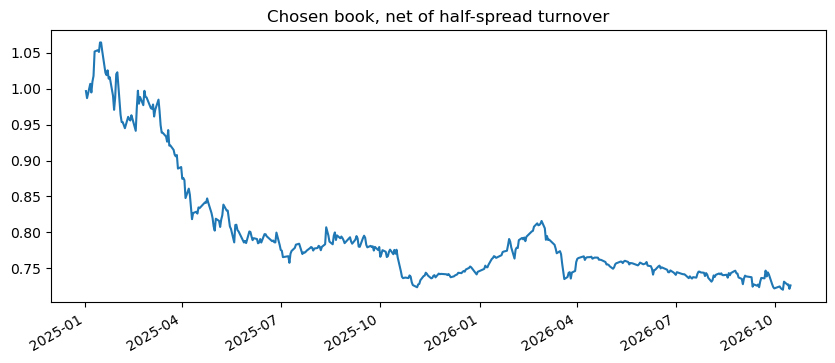

In [32]:
if result.chosen_returns.empty:
    print("No chosen book yet. The burn-in is 756 sessions plus 12 scored months.")
else:
    equity = (1.0 + result.chosen_returns).cumprod()
    equity.name = "chosen_equity"
    equity.plot(title="Chosen book, net of half-spread turnover", figsize=(10, 4))
    equity.tail()

In [33]:
if result.final_weights is None:
    print("No final weights.")
else:
    weights = result.final_weights.sort_values()
    print(
        f"names={len(weights)} sum={weights.sum():.6f} "
        f"gross={weights.abs().sum():.6f} max_abs={weights.abs().max():.6f}"
    )
    weights

names=20 sum=1.000000 gross=2.000000 max_abs=0.300000


In [34]:
if not result.plans:
    print("No simulated plans.")
else:
    latest = result.plans[-1]
    print(
        f"session={latest.session_date} status={latest.status} "
        f"sent_to_broker={latest.sent_to_broker} target_used={latest.target_return_used}"
    )
    display(pd.DataFrame([leg.__dict__ for leg in latest.legs]))
    display(pd.DataFrame(latest.skips))

session=2026-10-15 status=simulated sent_to_broker=False target_used=0.2


,client_order_id,instrument,phase,units,filled_units,status,attempts,position_fill,message
0,20261015r01CADSGD,CAD_SGD,reduce,2104.0,0,pending,0,REDUCE_ONLY,
1,20261015r02CORNUSD,CORN_USD,reduce,101.0,0,pending,0,REDUCE_ONLY,
2,20261015r05HKDJPY,HKD_JPY,reduce,-101.0,0,pending,0,REDUCE_ONLY,
3,20261015r06LTCUSD,LTC_USD,reduce,-4.0,0,pending,0,REDUCE_ONLY,
4,20261015r07NATGASUSD,NATGAS_USD,reduce,-75.0,0,pending,0,REDUCE_ONLY,
5,20261015r08XAGGBP,XAG_GBP,reduce,-5.0,0,pending,0,REDUCE_ONLY,
6,20261015i03EURAUD,EUR_AUD,increase,789.0,0,pending,0,OPEN_ONLY,
7,20261015i04EURCHF,EUR_CHF,increase,-2683.0,0,pending,0,OPEN_ONLY,
8,20261015i09XAUXAG,XAU_XAG,increase,6.0,0,pending,0,OPEN_ONLY,


""


In [35]:
comparison = result.covariance_comparison
if not comparison:
    print("No covariance comparison. The final window is shorter than the lookback.")
else:
    rows = []
    for name in ("ledoit_wolf", "sample", "one_factor"):
        matrix = np.asarray(comparison[name], dtype=float)
        eigenvalues = np.linalg.eigvalsh(matrix)
        rows.append(
            {
                "covariance": name,
                "min_eigenvalue": eigenvalues[0],
                "max_eigenvalue": eigenvalues[-1],
                "condition": eigenvalues[-1] / eigenvalues[0] if eigenvalues[0] > 0 else np.inf,
            }
        )
    print(f"Ledoit-Wolf shrinkage intensity={comparison['shrinkage']:.6f}")
    pd.DataFrame(rows).set_index("covariance")

Ledoit-Wolf shrinkage intensity=0.029967


## Practice account — run by hand

This is the only cell that can place an order. It builds a new plan from the latest completed session, the practice-account NAV, and the current practice positions. It does not resend a simulated research plan.

Set `SUBMIT_TODAY_TO_PRACTICE = True` only for the last session that has reached 17:00 New York. Bars after that close belong to the next session and are ignored until that session closes. The cell refuses a closed session more than four days behind the current New York date, and it refuses to send when that closed session has no plan. A dropped name is flattened in the reducing phase. If a reducing leg is rejected or partial, nothing further is sent.

In [41]:
import importlib
import oanda_portfolio.daily as _daily
import oanda_portfolio.plan as _plan
import oanda_portfolio.practice as _practice
importlib.reload(_daily)
importlib.reload(_plan)
importlib.reload(_practice)
from oanda_portfolio.daily import completed_sessions
from oanda_portfolio.plan import build_plan
from oanda_portfolio.practice import PlanStore, PracticeBroker, submit_plan

SUBMIT_TODAY_TO_PRACTICE = True

if not SUBMIT_TODAY_TO_PRACTICE:
    print("Practice submission is off. The cells above are research only.")
else:
    if not result.plans or result.final_weights is None:
        raise RuntimeError("no research plan exists for the latest session")
    closed_sessions = completed_sessions(closes.index)
    if len(closed_sessions) == 0:
        raise RuntimeError("no New York session has reached the 17:00 close")
    latest_session = str(pd.Timestamp(closed_sessions.max()).date())
    research = result.plans[-1]
    if research.session_date != latest_session:
        raise RuntimeError(
            f"latest session {latest_session} has no plan "
            f"(last plan is {research.session_date})"
        )
    today_ny = pd.Timestamp.now(tz="America/New_York").date()
    age_days = (today_ny - date.fromisoformat(latest_session)).days
    if age_days > 4:
        raise RuntimeError(
            f"latest session {latest_session} is {age_days} days behind New York date {today_ny}"
        )
    broker = PracticeBroker()
    current_units = broker.positions()
    names = sorted(set(research.weights) | set(current_units))
    execution = broker.execution_inputs(names)
    practice_plan = build_plan(
        session_date=latest_session,
        list_version=research.list_version,
        nav=execution.nav,
        weights=research.weights,
        mids={name: execution.mids[name] for name in research.weights},
        current_units=current_units,
        min_trade_units=config.min_trade_units,
        target_return_used=research.target_return_used,
        trade_steps=execution.trade_steps,
        quote_home_conversions={
            name: execution.quote_home_conversions[name]
            for name in research.weights
        },
        margin_rates={name: execution.margin_rates[name] for name in research.weights},
        margin_capacity=execution.margin_capacity,
        note="practice submission from notebooks/11_oanda_frontier.ipynb",
    )
    saved = submit_plan(practice_plan, broker, PlanStore(_root / "data" / "oanda_frontier_plans"))
    print(
        f"session={saved.session_date} status={saved.status} nav={saved.nav} "
        f"allocation_scale={saved.allocation_scale:.6f} "
        f"estimated_margin={saved.estimated_margin} "
        f"utilization={saved.margin_utilization:.2%} ceiling={saved.margin_budget}"
    )
    display(pd.DataFrame([leg.__dict__ for leg in saved.legs]))

WARNING oanda_portfolio.daily: Excluded open session(s) before the 17:00 New York close: 2026-10-16
INFO oandapyV20.oandapyV20: setting up API-client for environment practice
INFO oandapyV20.oandapyV20: performing request https://api-fxpractice.oanda.com/v3/accounts/101-011-29293917-001/summary
INFO oandapyV20.oandapyV20: performing request https://api-fxpractice.oanda.com/v3/accounts/101-011-29293917-001/openPositions
INFO oandapyV20.oandapyV20: performing request https://api-fxpractice.oanda.com/v3/accounts/101-011-29293917-001/summary
INFO oandapyV20.oandapyV20: performing request https://api-fxpractice.oanda.com/v3/accounts/101-011-29293917-001/instruments
INFO oandapyV20.oandapyV20: performing request https://api-fxpractice.oanda.com/v3/accounts/101-011-29293917-001/pricing
INFO oanda_portfolio.practice: Execution margin NAV=96850.48 used=8137.36 available=88766.69 utilization=0.08 target=25% ceiling=30% margin_call_percent=0.08397
INFO oanda_portfolio.plan: allocation scaled to 1

session=2026-10-15 status=complete nav=96850.4755 allocation_scale=1.386339 estimated_margin=24250.290917561924 utilization=25.03% ceiling=29071.21602


,client_order_id,instrument,phase,units,filled_units,status,attempts,position_fill,message
0,20261015r01CADSGD,CAD_SGD,reduce,10245.00,10245.00,filled,1,REDUCE_ONLY,
1,20261015r03CORNUSD,CORN_USD,reduce,817.00,817.00,filled,1,REDUCE_ONLY,
2,20261015r04EURAUD,EUR_AUD,reduce,-1873.00,-1873.00,filled,1,REDUCE_ONLY,
3,20261015r05EURCHF,EUR_CHF,reduce,3153.00,3153.00,filled,1,REDUCE_ONLY,
4,20261015r03LTCUSD,LTC_USD,reduce,-1.52,-1.52,filled,1,REDUCE_ONLY,
5,20261015r04NATGASUSD,NATGAS_USD,reduce,-798.00,-798.00,filled,1,REDUCE_ONLY,
6,20261015r05US2000USD,US2000_USD,reduce,-3.40,-3.40,filled,1,REDUCE_ONLY,
7,20261015r07XAGGBP,XAG_GBP,reduce,-302.00,-302.00,filled,1,REDUCE_ONLY,
8,20261015i02CADSGD,CAD_SGD,increase,-6365.00,-6365.00,filled,1,OPEN_ONLY,
9,20261015i03CHINAHHKD,CHINAH_HKD,increase,1.60,1.60,filled,1,OPEN_ONLY,
